# Your own bracket dataset: look inside the trained GNN

Run the cells from top to bottom (**Run All**). This reads what the other scripts made: `data/dataset.json` (from `generate_dataset.py`) and the weights `data/face_gnn.pt` (from `train_gnn.py`).

1. Overall numbers and the confusion matrix
2. **Part viewer**: draw one bracket as a face graph, true labels next to predicted labels
3. **Does the graph help?** Take away the easy clues and compare a model that sees neighbours with one that does not (this trains two small models, about a minute)

Labels: **plain** = every flat face, **hole** = the cylinder walls of drilled holes, **fillet** = the two cylinder faces of the bend.

In [1]:
import os, random, sys
sys.path.insert(0, os.getcwd())                     # open the notebook from the own_dataset folder
sys.path.insert(0, os.path.dirname(os.getcwd()))    # shared code: brep_gnn/

import json
import numpy as np
import torch
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.loader import DataLoader

from gnn_common import FaceGNN, FaceMLP, accuracy, evaluate, mean_iou, report, train
from train_gnn import DATA_DIR, LABELS, SEED, to_graph

%matplotlib inline
# (brep_to_graph.py switches matplotlib to a no-window mode; the line above turns charts back on in the notebook)

K = len(LABELS)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# rebuild exactly the split train_gnn.py used: 70% train / 15% validation / 15% test, by whole part
with open(os.path.join(DATA_DIR, "dataset.json")) as f:
    parts = json.load(f)
items = [(p, to_graph(p)) for p in parts]
random.seed(SEED)
random.shuffle(items)
n_train, n_val = int(0.70 * len(items)), int(0.15 * len(items))
train_items, val_items, test_items = items[:n_train], items[n_train:n_train + n_val], items[n_train + n_val:]
print(f"{len(items)} parts -> {len(train_items)} train / {len(val_items)} validation / {len(test_items)} test")

g0 = items[0][1]
model = FaceGNN(g0.x.shape[1], g0.edge_attr.shape[1], K).to(device)
model.load_state_dict(torch.load(os.path.join(DATA_DIR, "face_gnn.pt"), map_location=device))
model.eval()

C:\Users\UDAY\Documents\AnK-Progress\brep_gnn\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\UDAY\Documents\AnK-Progress\brep_gnn\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


300 parts -> 210 train / 45 validation / 45 test


FaceGNN(
  (inp): Linear(in_features=11, out_features=64, bias=True)
  (convs): ModuleList(
    (0-2): 3 x GATv2Conv(64, 16, heads=4)
  )
  (out): Linear(in_features=64, out_features=3, bias=True)
)

## 1. Overall numbers and the confusion matrix

face accuracy: 100.00%    mean IoU: 100.00%    (566 test faces)


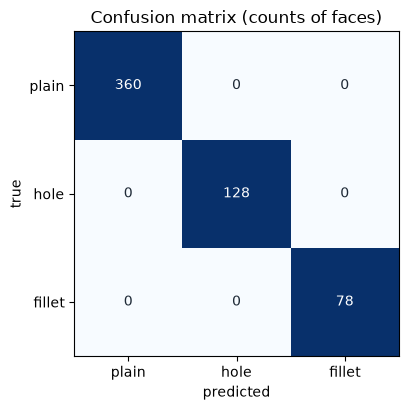

In [2]:
@torch.no_grad()
def predict(model, graphs):
    return [model(g.clone().to(device)).argmax(dim=1).cpu() for g in graphs]

test_graphs = [g for _, g in test_items]
preds = predict(model, test_graphs)
y_true = torch.cat([g.y for g in test_graphs])
cm = torch.bincount(y_true * K + torch.cat(preds), minlength=K * K).view(K, K)
print(f"face accuracy: {100 * accuracy(cm):.2f}%    mean IoU: {100 * mean_iou(cm):.2f}%    ({cm.sum().item()} test faces)")

fig, ax = plt.subplots(figsize=(4.8, 4.2), facecolor="white")
share = cm.float() / cm.sum(1, keepdim=True)
ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(LABELS); ax.set_yticks(range(K)); ax.set_yticklabels(LABELS)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
for i in range(K):
    for j in range(K):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", color="white" if share[i, j] > 0.5 else "#1f2a37")
ax.set_title("Confusion matrix (counts of faces)")
plt.tight_layout(); plt.show()

## 2. Part viewer
Each **dot is a face**, each **line a shared edge**. Line style shows the edge type: black = convex (outside corner), red = concave (inside corner), blue dashed = smooth (tangent blend).
Left: the true labels. Right: the GNN's prediction. A **red ring** marks a wrong face (you will rarely see one here).
Change the number in the last line to look at another test part.

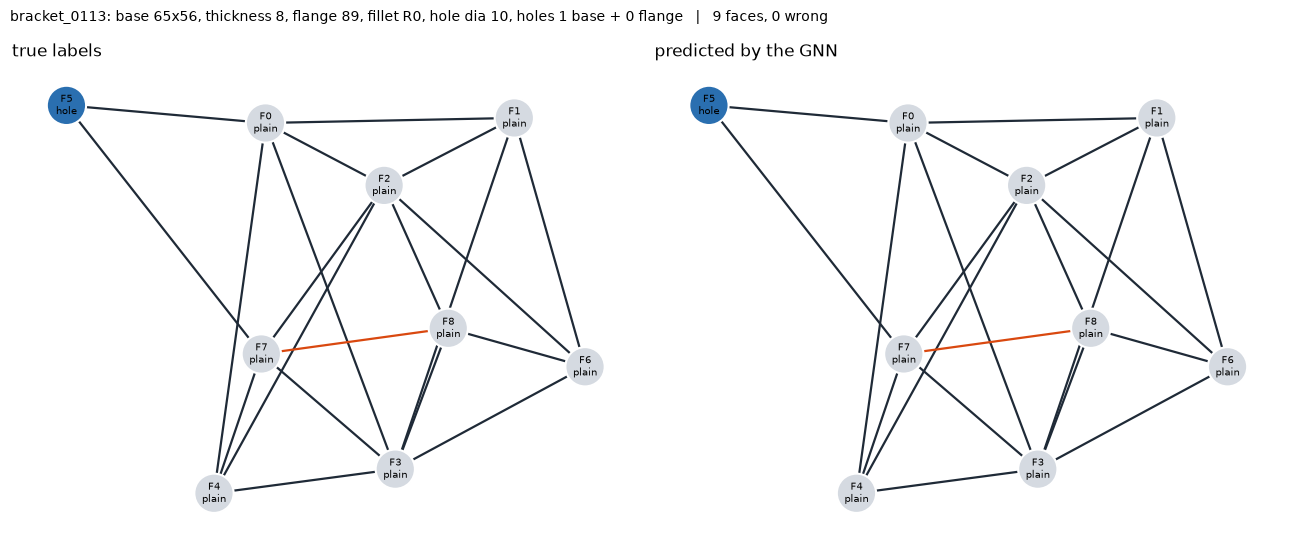

In [3]:
COLOURS = {"plain": "#d5dae1", "hole": "#2a6fb0", "fillet": "#e08a1e"}
EDGE_STYLE = {"convex": ("#1f2a37", "solid"), "concave": ("#d9480f", "solid"), "smooth": ("#2a6fb0", "dashed")}

def view_part(i, seed=3):
    part, g = test_items[i]
    y, p = g.y, preds[i]
    wrong = (p != y).numpy()
    G = nx.Graph()
    G.add_nodes_from(range(g.num_nodes))
    for e in part["edges"]:
        G.add_edge(e["a"], e["b"], kind=e["convexity"])
    pos = nx.spring_layout(G, seed=seed, k=1.2)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), facecolor="white")
    for ax, labels, title in ((axes[0], y, "true labels"), (axes[1], p, "predicted by the GNN")):
        for kind, (colour, style) in EDGE_STYLE.items():
            es = [(a, b) for a, b, d in G.edges(data=True) if d["kind"] == kind]
            nx.draw_networkx_edges(G, pos, edgelist=es, ax=ax, edge_color=colour, style=style, width=1.6)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_size=800,
                               node_color=[COLOURS[LABELS[int(l)]] for l in labels],
                               edgecolors=["#d9480f" if (ax is axes[1] and w) else "white" for w in wrong],
                               linewidths=[3 if (ax is axes[1] and w) else 1.5 for w in wrong])
        nx.draw_networkx_labels(G, pos, ax=ax, labels={n: f"F{n}\n{LABELS[int(labels[n])]}" for n in G}, font_size=7)
        ax.set_title(title, loc="left"); ax.axis("off")
    d = part["params"]
    fig.suptitle(f"{part['name']}: base {d['BASE_LENGTH']}x{d['BASE_WIDTH']}, thickness {d['THICKNESS']}, flange {d['FLANGE_HEIGHT']}, "
                 f"fillet R{d['FILLET_RADIUS']}, hole dia {d['HOLE_DIA']}, holes {d['HOLE_COUNT_BASE']} base + {d['HOLE_COUNT_FLANGE']} flange   |   "
                 f"{g.num_nodes} faces, {int(wrong.sum())} wrong", x=0.01, ha="left", fontsize=10)
    plt.tight_layout(); plt.show()

view_part(0)

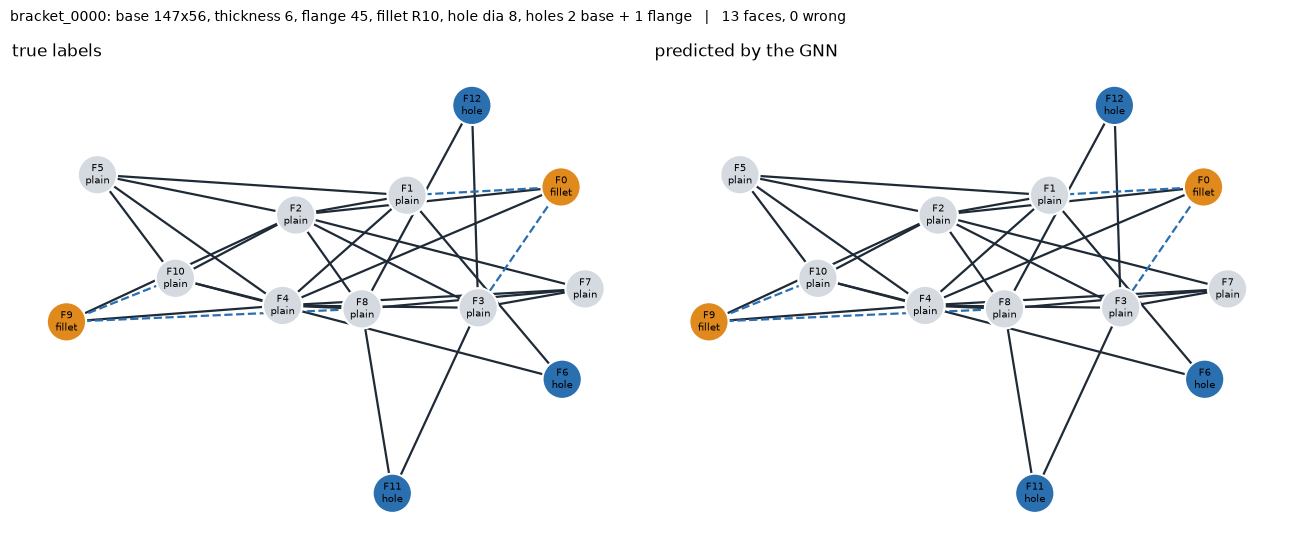

In [4]:
view_part(7)      # try any number from 0 to len(test_items) - 1

## 3. Does the graph help?
The trained model scores 100%, but so would a model that looks at each face alone. The clue is in the node features: a hole is a cylinder whose **axis points along X or Y**, a fillet is a cylinder whose axis points along **Z**. That is too easy.

So here we **hide the easy clues** (axis direction and position) and keep only the face type, area and radius. Then we train two small models on the same parts:
- **baseline**: sees one face at a time, no neighbours
- **GNN**: also sees the neighbouring faces and the edge types (convex / concave / smooth)

Both models are trained fresh below (60 epochs each). A hole wall is bounded by a concave or convex edge, a fillet is joined to its plates by *smooth* edges, which only the GNN can see.

In [5]:
HIDE = slice(5, 11)        # node feature columns 5-10 = axis direction (3) + centroid (3); 0-4 = face type, area, radius

def hide_clues(graphs):
    out = []
    for g in graphs:
        h = g.clone()
        h.x[:, HIDE] = 0
        out.append(h)
    return out

hard_train = hide_clues([g for _, g in train_items])
hard_val = hide_clues([g for _, g in val_items])
hard_test = hide_clues(test_graphs)

counts = torch.bincount(torch.cat([g.y for g in hard_train]), minlength=K).float()
weights = (counts.sum() / (K * counts)).to(device)
loaders = [DataLoader(s, batch_size=32, shuffle=(s is hard_train)) for s in (hard_train, hard_val, hard_test)]
n_in, n_edge = hard_train[0].x.shape[1], hard_train[0].edge_attr.shape[1]

torch.manual_seed(SEED)
print("training the baseline (no neighbours) ...")
mlp = train(FaceMLP(n_in, K), loaders[0], loaders[1], 60, device, "baseline", K, weights, print_every=20)
print("training the GNN ...")
gnn = train(FaceGNN(n_in, n_edge, K), loaders[0], loaders[1], 60, device, "gnn", K, weights, print_every=20)

cm_mlp, cm_gnn = evaluate(mlp, loaders[2], device, K), evaluate(gnn, loaders[2], device, K)
report("Baseline, clues hidden", cm_mlp, LABELS)
report("GNN, clues hidden", cm_gnn, LABELS)

training the baseline (no neighbours) ...
  [baseline] epoch   1  loss 1.0394  val acc 0.777


  [baseline] epoch  20  loss 0.1063  val acc 0.980


  [baseline] epoch  40  loss 0.0777  val acc 0.980


  [baseline] epoch  60  loss 0.0659  val acc 0.980
training the GNN ...
  [gnn] epoch   1  loss 0.9936  val acc 0.791


  [gnn] epoch  20  loss 0.0005  val acc 1.000


  [gnn] epoch  40  loss 0.0001  val acc 1.000


  [gnn] epoch  60  loss 0.0000  val acc 1.000

Baseline, clues hidden: test accuracy 98.59%, mean IoU 94.62% over 566 faces
  true \ predicted     plain    hole  fillet   per-class accuracy
  plain                  360       0       0   100.00%
  hole                     0     128       0   100.00%
  fillet                   0       8      70    89.74%

GNN, clues hidden: test accuracy 100.00%, mean IoU 100.00% over 566 faces
  true \ predicted     plain    hole  fillet   per-class accuracy
  plain                  360       0       0   100.00%
  hole                     0     128       0   100.00%
  fillet                   0       0      78   100.00%


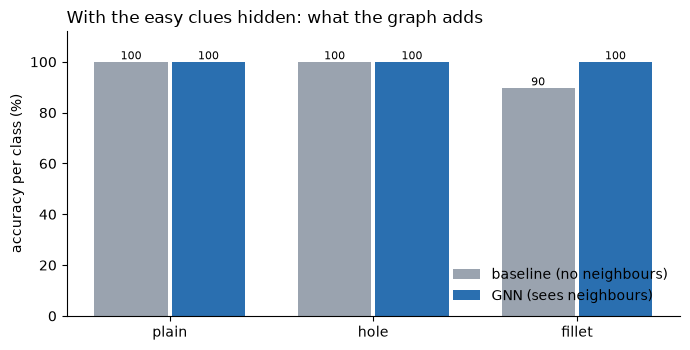

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.6), facecolor="white")
width = 0.36
base = [100 * cm_mlp[i, i].item() / cm_mlp[i].sum().item() for i in range(K)]
withg = [100 * cm_gnn[i, i].item() / cm_gnn[i].sum().item() for i in range(K)]
ax.bar(np.arange(K) - width / 2 - 0.01, base, width, label="baseline (no neighbours)", color="#9aa3af")
ax.bar(np.arange(K) + width / 2 + 0.01, withg, width, label="GNN (sees neighbours)", color="#2a6fb0")
for x, (b, w) in enumerate(zip(base, withg)):
    ax.text(x - width / 2 - 0.01, b + 1, f"{b:.0f}", ha="center", fontsize=8)
    ax.text(x + width / 2 + 0.01, w + 1, f"{w:.0f}", ha="center", fontsize=8)
ax.set_xticks(range(K)); ax.set_xticklabels(LABELS); ax.set_ylim(0, 112); ax.set_ylabel("accuracy per class (%)")
ax.set_title("With the easy clues hidden: what the graph adds", loc="left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()